<div align="center">

# KECERDASAN ARTIFISIAL UNTUK GEOFISIKA

## Estimasi Parameter Lapisan Bawah Permukaan Menggunakan Metode Seismik Refraksi dan Random Forest

<img src="https://www.unhas.ac.id/wp-content/uploads/2022/09/Logo-Resmi-Unhas-1.png" alt="Logo Universitas Hasanuddin" width="180">

**Disusun Oleh:**

Nama: Ariel Ar Rahman  
NIM: H061231016

**PROGRAM STUDI GEOFISIKA**  
**FAKULTAS MATEMATIKA DAN ILMU PENGETAHUAN ALAM**  
**UNIVERSITAS HASANUDDIN**

</div>

---

> **Catatan data:** Notebook ini menggunakan data sintetik/demonstrasi yang dibuat berdasarkan model seismik refraksi dua lapisan, bukan data pengukuran lapangan. Ganti data demonstrasi dengan data first-arrival lapangan yang telah melalui pemeriksaan kualitas sebelum menarik kesimpulan untuk lokasi nyata.

## 1. Pendahuluan

Seismik refraksi merupakan metode geofisika aktif yang memanfaatkan waktu tempuh gelombang seismik dari sumber menuju geofon. Pada kondisi tertentu, gelombang yang dibiaskan secara kritis di batas lapisan berkecepatan lebih tinggi dapat menjadi gelombang pertama yang terukur pada jarak tertentu. Kurva waktu tempuh terhadap jarak (*travel-time curve*) digunakan untuk menafsirkan kecepatan gelombang P (Vp) dan geometri lapisan bawah permukaan.

Interpretasi manual dapat memerlukan pemeriksaan kurva, pemilihan segmen, serta asumsi model. Dalam tugas ini, **Random Forest Regression** digunakan sebagai pendekatan kecerdasan artifisial untuk memperkirakan tiga parameter model dua lapisan dari sekumpulan waktu tiba pertama: Vp lapisan atas, Vp lapisan bawah, dan ketebalan lapisan atas. Model AI membantu mempercepat estimasi awal, tetapi tidak menggantikan pemeriksaan geofisika dan validasi lapangan.

## 2. Rumusan Masalah dan Tujuan

**Rumusan masalah**
1. Bagaimana merepresentasikan respons waktu tempuh pada model seismik refraksi dua lapisan?
2. Apakah Random Forest dapat mempelajari hubungan antara waktu tiba pertama dan parameter model bawah permukaan pada data demonstrasi?
3. Seberapa baik hasil estimasi model AI dibandingkan parameter model sintetik sebenarnya?

**Tujuan**
- Memahami hubungan offset geofon, waktu tiba pertama, dan kecepatan gelombang.
- Membentuk dataset sintetik untuk pelatihan dan pengujian Random Forest.
- Mengevaluasi prediksi Vp lapisan atas, Vp lapisan bawah, dan ketebalan lapisan atas menggunakan metrik regresi serta grafik.

**Batasan:** model hanya berupa dua lapisan horizontal, dengan Vp lapisan bawah lebih besar daripada Vp lapisan atas. Kondisi geologi nyata dapat lebih kompleks.

## 3. Dasar Teori

### 3.1 Seismik refraksi dua lapisan

Untuk dua lapisan horizontal dengan kecepatan gelombang P \(V_{p1}\) dan \(V_{p2}\), ketika \(V_{p2}>V_{p1}\), waktu tempuh gelombang langsung secara ideal dapat ditulis \(t_d=x/V_{p1}\). Waktu tempuh gelombang refraksi kritis pada pendekatan dua lapisan dapat dituliskan \(t_r=t_i+x/V_{p2}\), dengan \(t_i\) sebagai waktu intersep. Waktu tiba pertama ideal diambil dari nilai minimum kedua cabang tersebut.

Sudut kritis memenuhi \(\sin i_c=V_{p1}/V_{p2}\), dan untuk model lapisan horizontal, \(t_i=2h\cos i_c/V_{p1}\), dengan \(h\) ketebalan lapisan atas. Dalam praktik, heterogenitas, topografi, noise, picking first-arrival, serta geometri akuisisi memengaruhi kurva terukur.

### 3.2 Random Forest Regression

Random Forest membangun banyak pohon keputusan dari sampel dan subset fitur yang bervariasi, lalu menggabungkan prediksi pohon untuk menghasilkan estimasi regresi. Dalam notebook ini, fitur adalah waktu tiba pertama pada sejumlah offset geofon; targetnya adalah parameter model sintetik \(V_{p1}\), \(V_{p2}\), dan \(h\). Random Forest tidak memerlukan standardisasi fitur seperti beberapa algoritma lain, tetapi tetap membutuhkan data pelatihan yang representatif dan pengujian terpisah.

## 4. Metodologi dan Alur Kerja

1. Menentukan offset geofon dan rentang parameter model dua lapisan.
2. Menghasilkan banyak model sintetik dan menghitung waktu tiba pertama ideal, kemudian menambahkan noise kecil untuk meniru ketidakpastian pengukuran.
3. Menyusun matriks fitur dari waktu tiba pertama dan label target parameter model.
4. Membagi dataset menjadi data latih dan data uji.
5. Melatih `RandomForestRegressor`.
6. Mengukur performa dengan MAE, RMSE, dan R² untuk setiap target.
7. Membandingkan nilai sebenarnya dan prediksi, menampilkan contoh kurva waktu tempuh, serta memeriksa kepentingan fitur.

**Perangkat lunak:** Python, NumPy, Pandas, Matplotlib, dan scikit-learn.

In [1]:
# 5. Import pustaka
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
rng = np.random.default_rng(SEED)
print("Pustaka berhasil diimpor.")

Pustaka berhasil diimpor.


## 6. Membuat Geometri Akuisisi

Geometri demonstrasi menggunakan 24 geofon dengan spasi 5 m. Offset adalah jarak horizontal dari sumber ke geofon. Untuk menyederhanakan pemodelan, sumber dianggap berada di ujung lintasan dan model bawah permukaan terdiri atas dua lapisan horizontal.

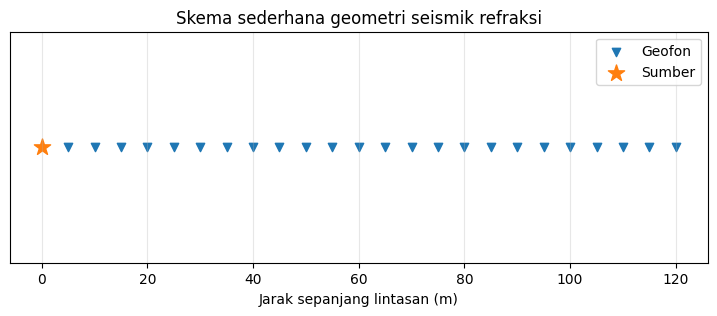

In [2]:
# Offset geofon (meter)
n_geophones = 24
spacing_m = 5.0
offsets = np.arange(1, n_geophones + 1) * spacing_m

plt.figure(figsize=(9, 3))
plt.scatter(offsets, np.zeros_like(offsets), marker='v', label='Geofon')
plt.scatter([0], [0], marker='*', s=150, label='Sumber')
plt.yticks([])
plt.xlabel('Jarak sepanjang lintasan (m)')
plt.title('Skema sederhana geometri seismik refraksi')
plt.legend()
plt.grid(axis='x', alpha=0.3)
plt.show()

## 7. Fungsi Model Waktu Tempuh Dua Lapisan

Fungsi berikut menghitung cabang gelombang langsung dan refraksi kritis. Waktu tiba pertama sintetik diambil sebagai minimum keduanya. Ini merupakan pendekatan sederhana untuk pembelajaran; bukan pemodelan ray-tracing umum untuk struktur berlapis kompleks.

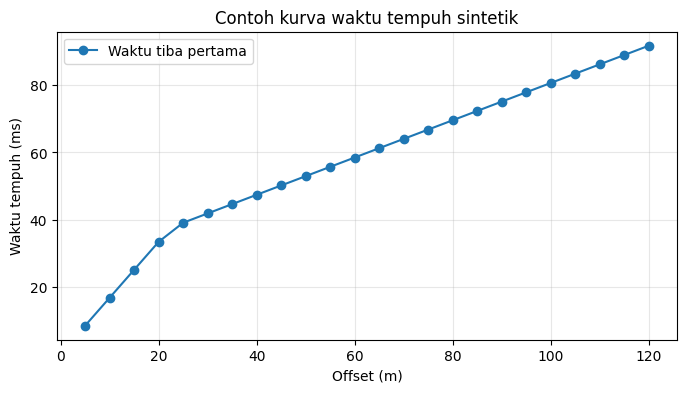

In [3]:
def first_arrival_two_layer(x, vp1, vp2, h):
    """Waktu tiba pertama ideal (detik) untuk model dua lapisan horizontal.
    x: offset (m), vp1/vp2: kecepatan (m/s), h: ketebalan lapisan atas (m).
    Syarat: vp2 > vp1.
    """
    if vp2 <= vp1:
        raise ValueError("Model refraksi kritis ini mensyaratkan vp2 > vp1.")
    t_direct = x / vp1
    sin_ic = vp1 / vp2
    cos_ic = np.sqrt(1.0 - sin_ic**2)
    t_intercept = 2.0 * h * cos_ic / vp1
    t_refracted = t_intercept + x / vp2
    return np.minimum(t_direct, t_refracted)

# Contoh kurva satu model
example = dict(vp1=600.0, vp2=1800.0, h=8.0)
t_example = first_arrival_two_layer(offsets, **example)
plt.figure(figsize=(8, 4))
plt.plot(offsets, t_example * 1000, 'o-', label='Waktu tiba pertama')
plt.xlabel('Offset (m)')
plt.ylabel('Waktu tempuh (ms)')
plt.title('Contoh kurva waktu tempuh sintetik')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 8. Membangun Dataset Sintetik

Setiap sampel mewakili satu model bawah permukaan dengan nilai Vp dan ketebalan yang diketahui. Waktu tempuh dihitung pada semua offset, lalu diberi noise acak kecil. Label target berasal dari parameter model yang digunakan untuk menghasilkan kurva. **Karena data ini sintetik, metrik hanya menunjukkan kemampuan model pada ruang parameter dan asumsi simulasi ini; metrik tersebut bukan bukti akurasi pada data lapangan.**

In [4]:
def make_synthetic_dataset(n_samples=1800, noise_ms=1.0, seed=42):
    local_rng = np.random.default_rng(seed)
    feature_rows, target_rows = [], []
    for _ in range(n_samples):
        vp1 = local_rng.uniform(300.0, 1200.0)
        vp2 = local_rng.uniform(max(vp1 + 250.0, 900.0), 3000.0)
        h = local_rng.uniform(2.0, 25.0)
        times = first_arrival_two_layer(offsets, vp1, vp2, h)
        noisy_times = times + local_rng.normal(0.0, noise_ms / 1000.0, size=len(offsets))
        # Waktu tiba harus tetap positif; noise tetap dipertahankan sebagai simulasi sederhana
        noisy_times = np.maximum(noisy_times, 0.0001)
        feature_rows.append(noisy_times)
        target_rows.append([vp1, vp2, h])
    feature_names = [f't_{int(x)}m_s' for x in offsets]
    X = pd.DataFrame(feature_rows, columns=feature_names)
    y = pd.DataFrame(target_rows, columns=['Vp_lapisan_1_m_s', 'Vp_lapisan_2_m_s', 'Ketebalan_lapisan_1_m'])
    return X, y

X, y = make_synthetic_dataset()
print('Jumlah sampel:', len(X))
print('Jumlah fitur waktu tiba:', X.shape[1])
print('Target:', list(y.columns))
display(pd.concat([X.iloc[:, :5], y], axis=1).head())

Jumlah sampel: 1800
Jumlah fitur waktu tiba: 24
Target: ['Vp_lapisan_1_m_s', 'Vp_lapisan_2_m_s', 'Ketebalan_lapisan_1_m']


,t_5m_s,t_10m_s,t_15m_s,t_20m_s,t_25m_s,Vp_lapisan_1_m_s,Vp_lapisan_2_m_s,Ketebalan_lapisan_1_m
0,0.005958,0.008083,0.013750,0.020197,0.024770,996.560444,2016.107260,21.747752
1,0.016873,0.029055,0.043680,0.058110,0.074270,339.423389,1224.007933,17.710126
2,0.008507,0.013159,0.021816,0.021522,0.025227,713.024198,2121.536252,5.215331
3,0.009908,0.022696,0.031270,0.037028,0.042772,450.275628,947.695354,4.071101
4,0.007278,0.013486,0.019675,0.028233,0.034672,710.198661,1372.979723,9.037002


## 9. Eksplorasi Data

Lihat distribusi target untuk memastikan rentang parameter sintetik yang dihasilkan. Rentang ini ditetapkan sebagai asumsi demonstrasi dan tidak mewakili semua kondisi geologi.

,Vp_lapisan_1_m_s,Vp_lapisan_2_m_s,Ketebalan_lapisan_1_m
count,1800.00,1800.00,1800.00
mean,750.26,2042.60,13.72
std,260.74,573.46,6.72
min,300.50,900.28,2.02
25%,528.10,1567.94,7.74
50%,749.46,2054.19,13.77
75%,983.02,2545.94,19.58
max,1199.95,2999.40,24.98


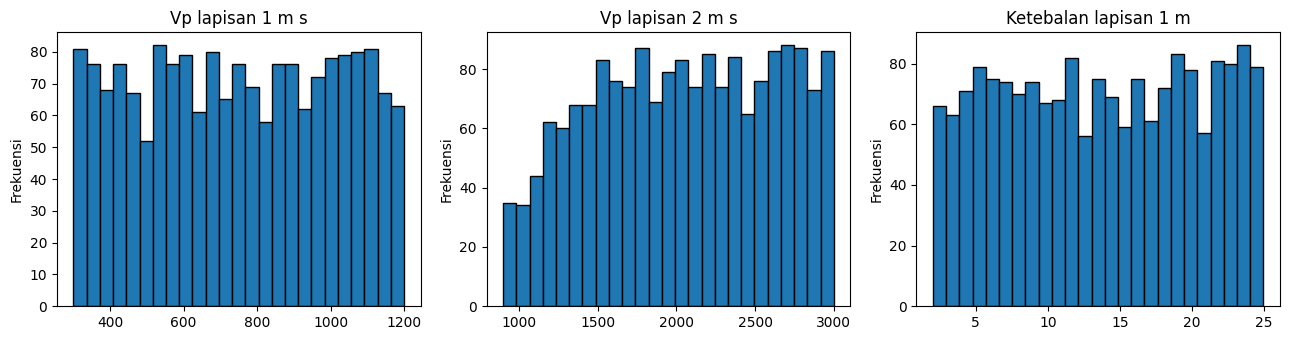

In [5]:
display(y.describe().round(2))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col in zip(axes, y.columns):
    ax.hist(y[col], bins=25, edgecolor='black')
    ax.set_title(col.replace('_', ' '))
    ax.set_ylabel('Frekuensi')
plt.tight_layout()
plt.show()

## 10. Pembagian Data dan Pelatihan Random Forest

Data uji disisihkan sebelum pelatihan. Model tidak menerima target data uji selama proses fit. Jumlah pohon dan parameter lain dapat disesuaikan, tetapi perubahan parameter sebaiknya dilakukan dengan validasi yang terencana.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)

rf = RandomForestRegressor(
    n_estimators=250,
    max_features=0.8,
    min_samples_leaf=2,
    random_state=SEED,
    n_jobs=-1
)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)
y_pred = pd.DataFrame(y_pred, columns=y.columns, index=y_test.index)
print(f'Data latih: {len(X_train)} sampel')
print(f'Data uji: {len(X_test)} sampel')
print('Pelatihan selesai.')

Data latih: 1440 sampel
Data uji: 360 sampel
Pelatihan selesai.


## 11. Evaluasi Model

MAE menunjukkan rata-rata besar kesalahan absolut; RMSE memberi penalti lebih besar pada kesalahan besar; R² membandingkan kecocokan model dengan baseline rata-rata target. Metrik untuk parameter berbeda satuan dan rentang, sehingga interpretasikan setiap target secara terpisah.

In [7]:
metrics = []
for col in y_test.columns:
    mae = mean_absolute_error(y_test[col], y_pred[col])
    rmse = np.sqrt(mean_squared_error(y_test[col], y_pred[col]))
    r2 = r2_score(y_test[col], y_pred[col])
    metrics.append({'Parameter': col, 'MAE': mae, 'RMSE': rmse, 'R2': r2})
metrics_df = pd.DataFrame(metrics)
display(metrics_df.round(4))

,Parameter,MAE,RMSE,R2
0,Vp_lapisan_1_m_s,32.3855,49.0478,0.9629
1,Vp_lapisan_2_m_s,136.7273,180.2266,0.9054
2,Ketebalan_lapisan_1_m,1.5595,2.1680,0.9013


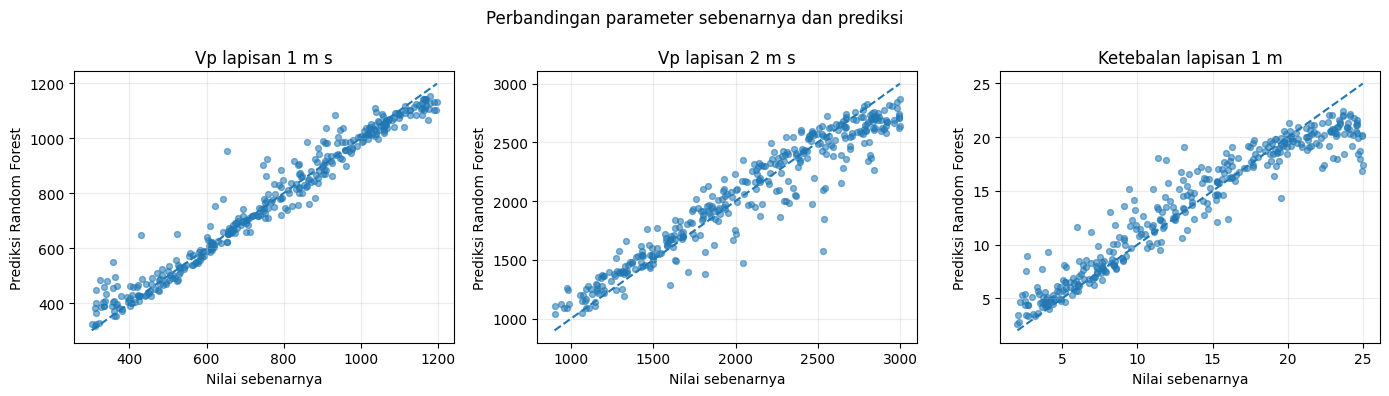

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, y_test.columns):
    ax.scatter(y_test[col], y_pred[col], alpha=0.55, s=18)
    low = min(y_test[col].min(), y_pred[col].min())
    high = max(y_test[col].max(), y_pred[col].max())
    ax.plot([low, high], [low, high], '--')
    ax.set_xlabel('Nilai sebenarnya')
    ax.set_ylabel('Prediksi Random Forest')
    ax.set_title(col.replace('_', ' '))
    ax.grid(alpha=0.25)
plt.suptitle('Perbandingan parameter sebenarnya dan prediksi')
plt.tight_layout()
plt.show()

## 12. Contoh Prediksi pada Satu Kurva Sintetik

Bagian ini menunjukkan bagaimana satu kurva waktu tiba dipakai sebagai input model. Nilai parameter sebenarnya disimpan hanya untuk evaluasi demonstrasi. Dalam penerapan lapangan, parameter sebenarnya biasanya tidak diketahui secara langsung dan perlu dibandingkan dengan interpretasi independen atau informasi bor/geologi.

Parameter sebenarnya (sintetik):


,Nilai sebenarnya
Vp_lapisan_1_m_s,750.354713
Vp_lapisan_2_m_s,1277.163968
Ketebalan_lapisan_1_m,11.828009


Parameter prediksi Random Forest:


,Prediksi
Vp_lapisan_1_m_s,746.717603
Vp_lapisan_2_m_s,1404.724861
Ketebalan_lapisan_1_m,14.443586


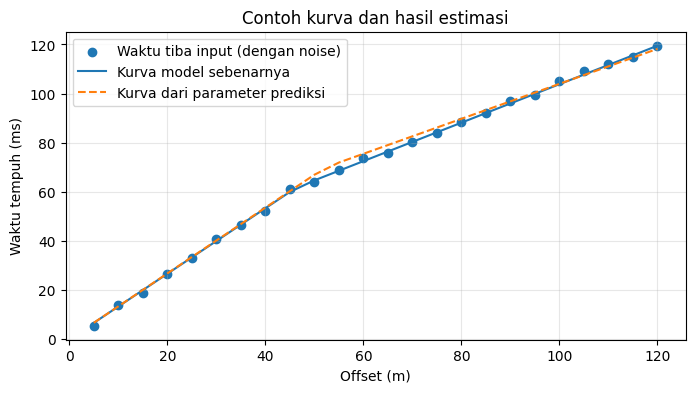

In [9]:
sample_idx = y_test.index[0]
true_params = y_test.loc[sample_idx]
pred_params = y_pred.loc[sample_idx]
observed_curve = X_test.loc[sample_idx].to_numpy()

print('Parameter sebenarnya (sintetik):')
display(true_params.to_frame('Nilai sebenarnya'))
print('Parameter prediksi Random Forest:')
display(pred_params.to_frame('Prediksi'))

plt.figure(figsize=(8, 4))
plt.scatter(offsets, observed_curve * 1000, label='Waktu tiba input (dengan noise)')
plt.plot(offsets, first_arrival_two_layer(offsets, true_params.iloc[0], true_params.iloc[1], true_params.iloc[2]) * 1000, label='Kurva model sebenarnya')
plt.plot(offsets, first_arrival_two_layer(offsets, pred_params.iloc[0], pred_params.iloc[1], pred_params.iloc[2]) * 1000, '--', label='Kurva dari parameter prediksi')
plt.xlabel('Offset (m)')
plt.ylabel('Waktu tempuh (ms)')
plt.title('Contoh kurva dan hasil estimasi')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 13. Kepentingan Fitur

Feature importance dari Random Forest memberikan gambaran relatif kontribusi fitur terhadap pemisahan pada pohon. Karena fitur merupakan waktu pada offset berbeda dan saling berkorelasi, nilai ini tidak boleh ditafsirkan sebagai bukti kausal atau langsung sebagai sensitivitas geofisika.

,Feature importance
t_120m_s,0.399938
t_115m_s,0.107720
t_10m_s,0.053134
t_55m_s,0.051675
t_50m_s,0.048644
t_110m_s,0.038978
t_15m_s,0.032002
t_60m_s,0.031984
t_45m_s,0.031703
t_40m_s,0.030824


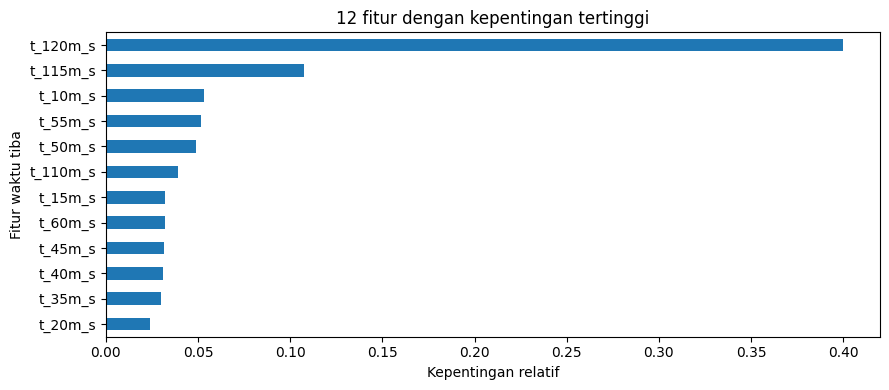

In [10]:
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
display(importance.head(10).to_frame('Feature importance'))

plt.figure(figsize=(9, 4))
importance.head(12).sort_values().plot(kind='barh')
plt.xlabel('Kepentingan relatif')
plt.ylabel('Fitur waktu tiba')
plt.title('12 fitur dengan kepentingan tertinggi')
plt.tight_layout()
plt.show()

## 14. Simpan Hasil

Hasil evaluasi dan tabel prediksi dapat disimpan untuk dokumentasi tugas. Berkas disimpan pada direktori kerja notebook. Data hasil tetap diberi label sebagai hasil demonstrasi sintetik.

In [11]:
results = y_test.add_suffix('_sebenarnya').join(y_pred.add_suffix('_prediksi'))
results.to_csv('hasil_prediksi_random_forest_seismik_refraksi.csv', index=True)
metrics_df.to_csv('evaluasi_model_random_forest.csv', index=False)
print('Berkas tersimpan:')
print('- hasil_prediksi_random_forest_seismik_refraksi.csv')
print('- evaluasi_model_random_forest.csv')

Berkas tersimpan:
- hasil_prediksi_random_forest_seismik_refraksi.csv
- evaluasi_model_random_forest.csv


## 15. Pembahasan

Saat menjalankan notebook, gunakan tabel metrik dan grafik aktual-versus-prediksi untuk membahas: (1) parameter mana yang paling mudah diperkirakan; (2) apakah prediksi cenderung menyimpang pada nilai kecil atau besar; (3) bagaimana noise dan rentang offset memengaruhi informasi yang tersedia; serta (4) apakah feature importance konsisten dengan bentuk kurva waktu tempuh. Jangan mengisi pembahasan dengan angka sebelum notebook dijalankan.

**Interpretasi geofisika:** Vp yang lebih tinggi sering berkaitan dengan material yang lebih kompak atau batuan lebih terkonsolidasi, tetapi hubungan ini tidak unik. Nilai Vp dipengaruhi litologi, porositas, rekahan, kejenuhan fluida, tekanan, dan kondisi pelapukan. Ketebalan yang diprediksi adalah ketebalan lapisan atas pada asumsi model dua lapisan horizontal, bukan otomatis kedalaman semua batas geologi.

## 16. Keterbatasan dan Pengembangan

- Data pelatihan sintetik mengikuti persamaan dan rentang yang dipilih; model dapat gagal pada kondisi di luar rentang ini.
- Model dua lapisan tidak merepresentasikan lapisan berkecepatan terbalik, topografi kompleks, lapisan miring, atau heterogenitas lateral.
- Noise yang ditambahkan bersifat sederhana dan belum meniru semua karakteristik picking lapangan.
- Random Forest mempelajari pemetaan statistik, bukan menyelesaikan inversi fisika secara eksplisit; beberapa kombinasi parameter dapat menghasilkan kurva serupa.
- Untuk aplikasi nyata, gunakan data first-arrival hasil picking yang telah dikontrol kualitas, dokumentasikan geometri dan satuan, validasi terhadap data independen, dan bandingkan dengan inversi/travel-time analysis konvensional. Hindari klaim akurasi lapangan berdasarkan data sintetik.

## 17. Kesimpulan

Notebook ini menunjukkan rancangan alur kerja integrasi metode geofisika seismik refraksi dengan AI Random Forest Regression. Kurva waktu tiba pertama pada offset geofon digunakan sebagai fitur untuk mengestimasi Vp lapisan pertama, Vp lapisan kedua, dan ketebalan lapisan pertama. Kinerja model dinilai melalui MAE, RMSE, R², dan grafik perbandingan. Kesimpulan numerik akhir harus ditulis setelah seluruh sel dijalankan. Hasil yang diperoleh dari dataset sintetik hanya membuktikan demonstrasi metode pada asumsi simulasi, bukan karakterisasi lokasi nyata.

## 18. Referensi

1. Sheriff, R. E., & Geldart, L. P. (1995). *Exploration Seismology* (2nd ed.). Cambridge University Press.
2. Reynolds, J. M. (2011). *An Introduction to Applied and Environmental Geophysics* (2nd ed.). Wiley-Blackwell.
3. Breiman, L. (2001). Random Forests. *Machine Learning, 45*, 5–32. https://doi.org/10.1023/A:1010933404324
4. scikit-learn developers. *RandomForestRegressor documentation*. https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html

---

**Catatan penyerahan:** Isi nama dan NIM pada halaman awal. Jalankan semua sel dari atas ke bawah, simpan notebook setelah output muncul, dan pastikan pembahasan menggunakan hasil yang benar-benar dihasilkan oleh notebook.